In [1]:
# 1. Imports and device
import copy
import random
import time
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch
import torch.nn as nn
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

Using device: cuda


In [2]:
# 2. Dataset and preprocessing
base_dir = Path.cwd()
if not (base_dir / "imagenette2-160").exists() and (base_dir.parent / "imagenette2-160").exists():
    base_dir = base_dir.parent

data_dir = base_dir / "imagenette2-160"
if not data_dir.exists():
    raise FileNotFoundError(f"Could not find dataset folder: {data_dir}")

mean = [0.485, 0.456, 0.406]
std = [0.229, 0.224, 0.225]

transform_no_aug = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

transform_aug = transforms.Compose([
    transforms.Resize((160, 160)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2, hue=0.05),
    transforms.ToTensor(),
    transforms.Normalize(mean, std)
])

train_dataset = datasets.ImageFolder(data_dir / "train", transform=transform_no_aug)
val_dataset = datasets.ImageFolder(data_dir / "val", transform=transform_no_aug)

class_names = train_dataset.classes
num_classes = len(class_names)
assert class_names == val_dataset.classes

batch_size = 64
num_workers = 4

print("Classes:", class_names)
print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Classes: ['n01440764', 'n02102040', 'n02979186', 'n03000684', 'n03028079', 'n03394916', 'n03417042', 'n03425413', 'n03445777', 'n03888257']
Training images: 9469
Validation images: 3925


In [3]:
# 3. Initial three-layer CNN
train_loader = DataLoader(
    train_dataset, batch_size=batch_size, shuffle=True,
    num_workers=num_workers, pin_memory=(device.type == "cuda"),
    persistent_workers=(num_workers > 0)
)

val_loader = DataLoader(
    val_dataset, batch_size=batch_size, shuffle=False,
    num_workers=num_workers, pin_memory=(device.type == "cuda"),
    persistent_workers=(num_workers > 0)
)

class NeuralNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.conv_stack = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.AdaptiveAvgPool2d((1, 1))
        )
        self.flatten = nn.Flatten()
        self.linear_stack = nn.Sequential(
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        x = self.conv_stack(x)
        x = self.flatten(x)
        return self.linear_stack(x)

model = NeuralNetwork().to(device)
images, labels = next(iter(train_loader))
print("Output shape:", model(images.to(device)).shape)

Output shape: torch.Size([64, 10])


In [4]:
# 4. Train the initial CNN
epochs = 20
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(epochs):
    start = time.perf_counter()
    model.train()
    total_loss = 0
    correct = 0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * images.size(0)
        correct += (outputs.argmax(1) == labels).sum().item()

    train_loss = total_loss / len(train_dataset)
    train_acc = correct / len(train_dataset)

    model.eval()
    val_loss_sum = 0
    val_correct = 0
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            val_loss_sum += loss.item() * images.size(0)
            val_correct += (outputs.argmax(1) == labels).sum().item()

    val_loss = val_loss_sum / len(val_dataset)
    val_acc = val_correct / len(val_dataset)

    if device.type == "cuda":
        torch.cuda.synchronize()
    elapsed = time.perf_counter() - start

    print(
        f"Epoch {epoch + 1}/{epochs} | Train Loss: {train_loss:.4f} | "
        f"Train Acc: {train_acc:.2%} | Val Loss: {val_loss:.4f} | "
        f"Val Acc: {val_acc:.2%} | Time: {elapsed:.2f}s"
    )

del train_loader, images, labels


Epoch 1/20 | Train Loss: 2.0748 | Train Acc: 24.30% | Val Loss: 1.9604 | Val Acc: 30.27% | Time: 12.82s
Epoch 2/20 | Train Loss: 1.8536 | Train Acc: 34.22% | Val Loss: 1.7782 | Val Acc: 38.85% | Time: 2.80s
Epoch 3/20 | Train Loss: 1.7069 | Train Acc: 41.12% | Val Loss: 1.6618 | Val Acc: 42.45% | Time: 2.79s
Epoch 4/20 | Train Loss: 1.6127 | Train Acc: 44.85% | Val Loss: 1.5500 | Val Acc: 47.64% | Time: 2.79s
Epoch 5/20 | Train Loss: 1.5157 | Train Acc: 48.51% | Val Loss: 1.4783 | Val Acc: 50.68% | Time: 2.78s
Epoch 6/20 | Train Loss: 1.4365 | Train Acc: 50.84% | Val Loss: 1.5513 | Val Acc: 46.11% | Time: 2.80s
Epoch 7/20 | Train Loss: 1.3818 | Train Acc: 53.60% | Val Loss: 1.3551 | Val Acc: 55.31% | Time: 2.80s
Epoch 8/20 | Train Loss: 1.3253 | Train Acc: 55.63% | Val Loss: 1.3374 | Val Acc: 55.72% | Time: 2.78s
Epoch 9/20 | Train Loss: 1.2845 | Train Acc: 57.17% | Val Loss: 1.3187 | Val Acc: 55.97% | Time: 2.81s
Epoch 10/20 | Train Loss: 1.2259 | Train Acc: 59.38% | Val Loss: 1.2457 

In [5]:
# 5. Compare CNN architectures
class ArchitectureCNN(nn.Module):
    def __init__(self, channels):
        super().__init__()
        layers = []
        in_channels = 3

        for out_channels in channels:
            layers.extend([
                nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1),
                nn.ReLU(),
                nn.MaxPool2d(2)
            ])
            in_channels = out_channels

        layers.append(nn.AdaptiveAvgPool2d((1, 1)))
        self.conv_stack = nn.Sequential(*layers)
        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(channels[-1], 64),
            nn.ReLU(),
            nn.Linear(64, num_classes)
        )

    def forward(self, x):
        return self.classifier(self.conv_stack(x))


architectures = {
    "CNN 1": [16, 32, 64],
    "CNN 2": [32, 64, 128],
    "CNN 3": [32, 64, 256],
    "CNN 4": [64, 128, 256],
    "CNN 5": [16, 32, 64, 128],
    "CNN 6": [32, 64, 128, 256],
    "CNN 7": [32, 64, 128, 128],
    "CNN 8": [64, 128, 256, 512]
}

architecture_results = {}

for name, channels in architectures.items():
    print(f"\nTraining {name}: {channels}")
    random.seed(42)
    torch.manual_seed(42)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    generator = torch.Generator().manual_seed(42)
    train_loader_arch = DataLoader(
        train_dataset, batch_size=batch_size, shuffle=True,
        num_workers=num_workers, pin_memory=(device.type == "cuda"),
        persistent_workers=(num_workers > 0), generator=generator
    )

    model = ArchitectureCNN(channels).to(device)
    parameters = sum(p.numel() for p in model.parameters())
    optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}
    best_val_acc = 0.0
    best_epoch = 0
    start = time.perf_counter()

    for epoch in range(epochs):
        model.train()
        loss_sum = 0.0
        correct = 0

        for images, labels in train_loader_arch:
            images, labels = images.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(images)
            loss = loss_fn(outputs, labels)
            loss.backward()
            optimizer.step()
            loss_sum += loss.item() * images.size(0)
            correct += (outputs.argmax(1) == labels).sum().item()

        train_loss = loss_sum / len(train_dataset)
        train_acc = correct / len(train_dataset)

        model.eval()
        val_loss_sum = 0.0
        val_correct = 0
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = loss_fn(outputs, labels)
                val_loss_sum += loss.item() * images.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()

        val_loss = val_loss_sum / len(val_dataset)
        val_acc = val_correct / len(val_dataset)

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if val_acc > best_val_acc:
            best_val_acc = val_acc
            best_epoch = epoch + 1
        
        print(
            f"Epoch {epoch + 1}/{epochs} | Train Acc: {train_acc:.2%} | "
            f"Val Acc: {val_acc:.2%}"
        )

    if device.type == "cuda":
        torch.cuda.synchronize()
    total_time = time.perf_counter() - start

    architecture_results[name] = {
        "channels": channels,
        "layers": len(channels),
        "parameters": parameters,
        "best_val_acc": best_val_acc,
        "best_epoch": best_epoch,
        "final_val_acc": val_acc,
        "training_time": total_time,
        "history": history
    }

    del model, optimizer, train_loader_arch
    if device.type == "cuda":
        torch.cuda.empty_cache()

architecture_table = pd.DataFrame([
    {
        "Model": name,
        "Conv Layers": item["layers"],
        "Channels": str(item["channels"]),
        "Parameters": item["parameters"],
        "Best Val Accuracy": item["best_val_acc"],
        "Best Epoch": item["best_epoch"],
        "Training Time (s)": item["training_time"]
    }
    for name, item in architecture_results.items()
]).sort_values("Best Val Accuracy", ascending=False)

display(architecture_table.style.format({
    "Best Val Accuracy": "{:.2%}",
    "Training Time (s)": "{:.1f}",
    "Parameters": "{:,}"
}))


Training CNN 1: [16, 32, 64]
Epoch 1/20 | Train Acc: 21.05% | Val Acc: 24.64%
Epoch 2/20 | Train Acc: 31.29% | Val Acc: 31.64%
Epoch 3/20 | Train Acc: 37.05% | Val Acc: 39.85%
Epoch 4/20 | Train Acc: 41.59% | Val Acc: 42.83%
Epoch 5/20 | Train Acc: 44.98% | Val Acc: 45.91%
Epoch 6/20 | Train Acc: 47.46% | Val Acc: 44.38%
Epoch 7/20 | Train Acc: 49.66% | Val Acc: 47.57%
Epoch 8/20 | Train Acc: 51.97% | Val Acc: 52.56%
Epoch 9/20 | Train Acc: 53.70% | Val Acc: 53.73%
Epoch 10/20 | Train Acc: 55.75% | Val Acc: 54.50%
Epoch 11/20 | Train Acc: 56.81% | Val Acc: 56.74%
Epoch 12/20 | Train Acc: 58.09% | Val Acc: 57.81%
Epoch 13/20 | Train Acc: 59.14% | Val Acc: 57.68%
Epoch 14/20 | Train Acc: 60.25% | Val Acc: 60.31%
Epoch 15/20 | Train Acc: 61.02% | Val Acc: 59.67%
Epoch 16/20 | Train Acc: 61.46% | Val Acc: 61.22%
Epoch 17/20 | Train Acc: 62.60% | Val Acc: 60.48%


KeyboardInterrupt: 

In [6]:
# 6. Define the selected CNN and experiment configurations
selected_channels = [64, 128, 256, 512]

class FinalCNN(nn.Module):
    def __init__(self, use_bn=False, dropout_p=0.0):
        super().__init__()
        layers = []
        in_channels = 3

        for out_channels in selected_channels:
            layers.append(nn.Conv2d(in_channels, out_channels, kernel_size=3, padding=1))
            if use_bn:
                layers.append(nn.BatchNorm2d(out_channels))
            layers.extend([nn.ReLU(), nn.MaxPool2d(2)])
            in_channels = out_channels

        layers.append(nn.AdaptiveAvgPool2d((1, 1)))
        self.features = nn.Sequential(*layers)
        classifier = [nn.Flatten(), nn.Linear(selected_channels[-1], 64), nn.ReLU()]
        if dropout_p > 0:
            classifier.append(nn.Dropout(dropout_p))
        classifier.append(nn.Linear(64, num_classes))
        self.classifier = nn.Sequential(*classifier)

    def forward(self, x):
        return self.classifier(self.features(x))


experiment_configs = {
    "Baseline": {"use_bn": False, "dropout_p": 0.0, "augmentation": False},
    "BatchNorm": {"use_bn": True, "dropout_p": 0.0, "augmentation": False},
    "Dropout": {"use_bn": False, "dropout_p": 0.3, "augmentation": False},
    "Augmentation": {"use_bn": False, "dropout_p": 0.0, "augmentation": True}
}

In [8]:
# 7. Train all eight configurations

import time
import random
import copy
import gc
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

selected_channels = [64, 128, 256, 512]

epochs = 20
batch_size = 64
learning_rate = 0.001

experiment_configs = {
    "1. Baseline": {
        "use_bn": False, "dropout_p": 0.0, "augmentation": False
    },
    "2. BatchNorm": {
        "use_bn": True, "dropout_p": 0.0, "augmentation": False
    },
    "3. Dropout": {
        "use_bn": False, "dropout_p": 0.3, "augmentation": False
    },
    "4. Augmentation": {
        "use_bn": False, "dropout_p": 0.0, "augmentation": True
    },
    "5. BatchNorm + Dropout": {
        "use_bn": True, "dropout_p": 0.3, "augmentation": False
    },
    "6. BatchNorm + Augmentation": {
        "use_bn": True, "dropout_p": 0.0, "augmentation": True
    },
    "7. Dropout + Augmentation": {
        "use_bn": False, "dropout_p": 0.3, "augmentation": True
    },
    "8. All three methods": {
        "use_bn": True, "dropout_p": 0.3, "augmentation": True
    }
}


def run_experiment(name, config):

    experiment_start = time.perf_counter()

    random.seed(42)
    torch.manual_seed(42)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(42)

    train_transform = (
        transform_aug if config["augmentation"]
        else transform_no_aug
    )

    experiment_train_dataset = datasets.ImageFolder(
        data_dir / "train",
        transform=train_transform
    )

    generator = torch.Generator().manual_seed(42)

    experiment_train_loader = DataLoader(
        experiment_train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=(device.type == "cuda"),
        persistent_workers=(num_workers > 0),
        generator=generator
    )

    model = FinalCNN(
        use_bn=config["use_bn"],
        dropout_p=config["dropout_p"]
    ).to(device)

    loss_fn = nn.CrossEntropyLoss()

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": [],
        "epoch_time": []
    }

    best_val_acc = 0.0
    best_epoch = 0
    best_state = copy.deepcopy(model.state_dict())

    for epoch in range(epochs):

        epoch_start = time.perf_counter()

        # Training
        model.train()

        train_loss_sum = 0.0
        train_correct = 0

        for images, labels in experiment_train_loader:

            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()

            outputs = model(images)
            loss = loss_fn(outputs, labels)

            loss.backward()
            optimizer.step()

            train_loss_sum += loss.item() * images.size(0)
            train_correct += (outputs.argmax(1) == labels).sum().item()

        train_loss = train_loss_sum / len(experiment_train_dataset)
        train_acc = train_correct / len(experiment_train_dataset)

        # Validation
        model.eval()

        val_loss_sum = 0.0
        val_correct = 0

        with torch.no_grad():

            for images, labels in val_loader:

                images, labels = images.to(device), labels.to(device)

                outputs = model(images)
                loss = loss_fn(outputs, labels)

                val_loss_sum += loss.item() * images.size(0)
                val_correct += (outputs.argmax(1) == labels).sum().item()

        val_loss = val_loss_sum / len(val_dataset)
        val_acc = val_correct / len(val_dataset)

        if val_acc > best_val_acc:

            best_val_acc = val_acc
            best_epoch = epoch + 1
            best_state = copy.deepcopy(model.state_dict())

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)
        history["train_acc"].append(train_acc)
        history["val_acc"].append(val_acc)

        if device.type == "cuda":
            torch.cuda.synchronize()

        epoch_time = time.perf_counter() - epoch_start
        history["epoch_time"].append(epoch_time)

        print(
            f"{name} | Epoch {epoch+1}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc:.2%} | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc:.2%} | "
            f"Time: {epoch_time:.2f}s"
        )

    # Evaluate the best checkpoint
    model.load_state_dict(best_state)
    model.eval()

    y_true, y_pred = [], []

    with torch.no_grad():

        for images, labels in val_loader:

            outputs = model(images.to(device))

            y_pred.extend(outputs.argmax(1).cpu().tolist())
            y_true.extend(labels.tolist())

    checkpoint_name = (
        f"cnn_{name.lower().replace(' ', '_').replace('+', 'plus')}.pth"
    )

    torch.save(best_state, checkpoint_name)

    if device.type == "cuda":
        torch.cuda.synchronize()

    total_time = time.perf_counter() - experiment_start
    avg_epoch_time = sum(history["epoch_time"]) / epochs

    result = {
        "configuration": config,
        "history": history,
        "best_val_acc": best_val_acc,
        "best_epoch": best_epoch,
        "final_val_acc": history["val_acc"][-1],
        "avg_epoch_time": avg_epoch_time,
        "total_time": total_time,
        "labels": y_true,
        "predictions": y_pred,
        "checkpoint": checkpoint_name
    }

    print(
        f"\n{name} completed | "
        f"Best accuracy: {best_val_acc:.2%} | "
        f"Best epoch: {best_epoch} | "
        f"Avg epoch: {avg_epoch_time:.2f}s | "
        f"Total time: {total_time:.2f}s\n"
    )

    del model, optimizer, experiment_train_loader, experiment_train_dataset
    gc.collect()

    if device.type == "cuda":
        torch.cuda.empty_cache()

    return result


all_experiments_start = time.perf_counter()

final_results = {}

for experiment_name, config in experiment_configs.items():

    print(f"\n{'=' * 65}")
    print(experiment_name)
    print(f"{'=' * 65}")

    final_results[experiment_name] = run_experiment(
        experiment_name,
        config
    )

if device.type == "cuda":
    torch.cuda.synchronize()

total_experiments_time = time.perf_counter() - all_experiments_start

print(f"\nTotal time for all experiments: "
      f"{total_experiments_time / 60:.2f} minutes")


1. Baseline
1. Baseline | Epoch 1/20 | Train Loss: 2.1001 | Train Acc: 23.17% | Val Loss: 1.9326 | Val Acc: 32.28% | Time: 17.21s
1. Baseline | Epoch 2/20 | Train Loss: 1.7856 | Train Acc: 37.40% | Val Loss: 1.6756 | Val Acc: 40.66% | Time: 6.87s
1. Baseline | Epoch 3/20 | Train Loss: 1.5850 | Train Acc: 45.74% | Val Loss: 1.5768 | Val Acc: 45.94% | Time: 6.54s
1. Baseline | Epoch 4/20 | Train Loss: 1.4182 | Train Acc: 51.82% | Val Loss: 1.3243 | Val Acc: 56.05% | Time: 6.50s
1. Baseline | Epoch 5/20 | Train Loss: 1.2641 | Train Acc: 57.69% | Val Loss: 1.2048 | Val Acc: 60.20% | Time: 6.55s
1. Baseline | Epoch 6/20 | Train Loss: 1.1455 | Train Acc: 62.20% | Val Loss: 1.1329 | Val Acc: 63.62% | Time: 6.59s
1. Baseline | Epoch 7/20 | Train Loss: 1.0459 | Train Acc: 64.91% | Val Loss: 1.0804 | Val Acc: 65.32% | Time: 6.66s
1. Baseline | Epoch 8/20 | Train Loss: 0.9627 | Train Acc: 68.51% | Val Loss: 1.0346 | Val Acc: 67.87% | Time: 6.62s
1. Baseline | Epoch 9/20 | Train Loss: 0.8776 | Tr

In [9]:
# 8. Summarize the selected-architecture experiments

table_rows = []

for name, result in final_results.items():

    config = result["configuration"]

    if not config["use_bn"] and config["dropout_p"] == 0 and not config["augmentation"]:
        notes = "Baseline"
    else:
        methods = []

        if config["use_bn"]:
            methods.append("BatchNorm")

        if config["dropout_p"] > 0:
            methods.append(f"Dropout (p={config['dropout_p']})")

        if config["augmentation"]:
            methods.append("Horizontal Flip + ColorJitter")

        notes = " + ".join(methods)

    table_rows.append({
        "Configuration": name,
        "BatchNorm": "Yes" if config["use_bn"] else "No",
        "Dropout": f'{config["dropout_p"]:.1f}' if config["dropout_p"] else "No",
        "Augmentation": "Yes" if config["augmentation"] else "No",
        "Best validation accuracy": result["best_val_acc"],
        "Best epoch": result["best_epoch"],
        "Final validation accuracy": result["final_val_acc"],
        "Avg. epoch time (s)": result["avg_epoch_time"],
        "Total time (s)": result["total_time"],
        "Notes": notes
    })

results_table = pd.DataFrame(table_rows)

results_table = results_table.sort_values(
    "Best validation accuracy",
    ascending=False
).reset_index(drop=True)

display(results_table.style.format({
    "Best validation accuracy": "{:.2%}",
    "Final validation accuracy": "{:.2%}",
    "Avg. epoch time (s)": "{:.2f}",
    "Total time (s)": "{:.2f}"
}))

,Configuration,BatchNorm,Dropout,Augmentation,Best validation accuracy,Best epoch,Final validation accuracy,Avg. epoch time (s),Total time (s),Notes
0,4. Augmentation,No,No,Yes,78.57%,19,77.78%,7.37,148.26,Horizontal Flip + ColorJitter
1,2. BatchNorm,Yes,No,No,78.22%,19,68.13%,8.38,168.77,BatchNorm
2,1. Baseline,No,No,No,78.09%,20,78.09%,7.04,141.84,Baseline
3,3. Dropout,No,0.3,No,76.69%,20,76.69%,7.03,141.54,Dropout (p=0.3)
4,6. BatchNorm + Augmentation,Yes,No,Yes,75.24%,9,60.87%,8.95,180.04,BatchNorm + Horizontal Flip + ColorJitter
5,7. Dropout + Augmentation,No,0.3,Yes,75.24%,20,75.24%,7.71,155.25,Dropout (p=0.3) + Horizontal Flip + ColorJitter
6,5. BatchNorm + Dropout,Yes,0.3,No,73.48%,10,62.62%,8.67,174.47,BatchNorm + Dropout (p=0.3)
7,8. All three methods,Yes,0.3,Yes,71.39%,8,62.14%,8.95,180.20,BatchNorm + Dropout (p=0.3) + Horizontal Flip + ColorJitter


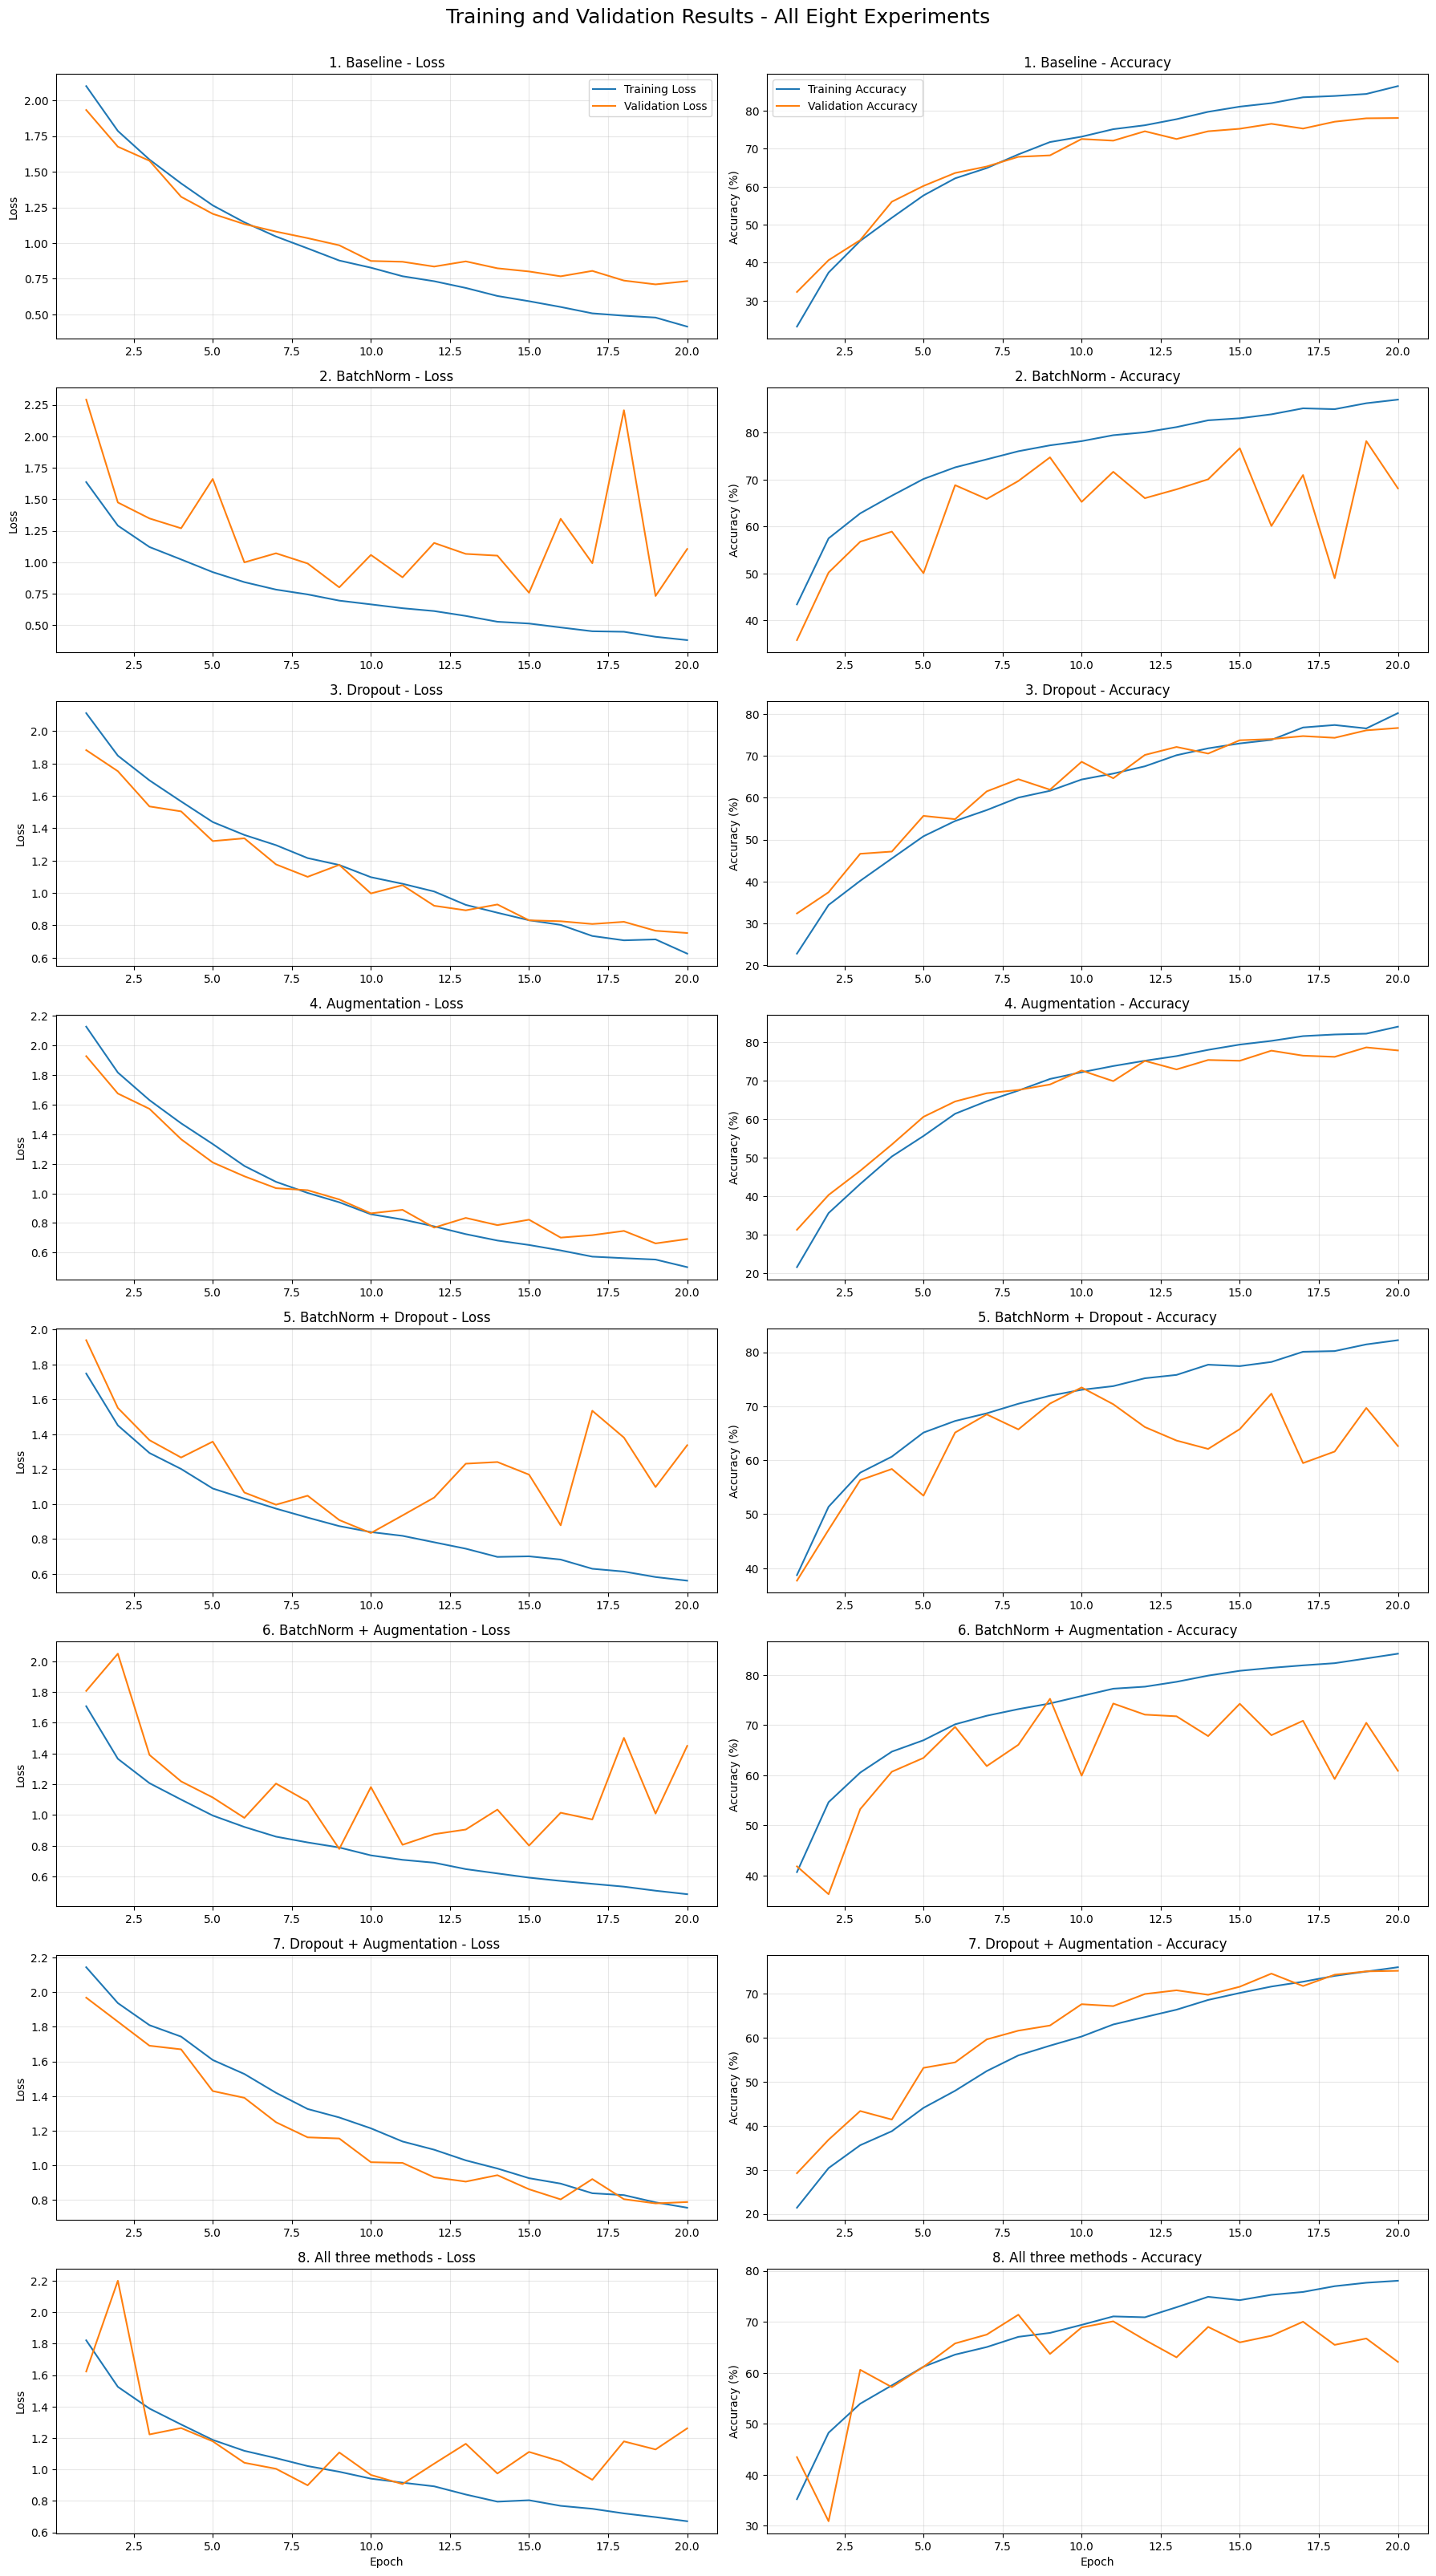

In [10]:
# 9. Plot loss and accuracy curves

fig, axes = plt.subplots(8, 2, figsize=(18, 32))

fig.suptitle(
    "Training and Validation Results - All Eight Experiments",
    fontsize=18,
    y=1.002
)

for i, (name, result) in enumerate(final_results.items()):

    history = result["history"]
    epoch_range = range(1, epochs + 1)

    # Loss
    axes[i, 0].plot(
        epoch_range,
        history["train_loss"],
        label="Training Loss"
    )

    axes[i, 0].plot(
        epoch_range,
        history["val_loss"],
        label="Validation Loss"
    )

    axes[i, 0].set_title(f"{name} - Loss")
    axes[i, 0].set_ylabel("Loss")
    axes[i, 0].grid(True, alpha=0.3)

    # Accuracy
    axes[i, 1].plot(
        epoch_range,
        [x * 100 for x in history["train_acc"]],
        label="Training Accuracy"
    )

    axes[i, 1].plot(
        epoch_range,
        [x * 100 for x in history["val_acc"]],
        label="Validation Accuracy"
    )

    axes[i, 1].set_title(f"{name} - Accuracy")
    axes[i, 1].set_ylabel("Accuracy (%)")
    axes[i, 1].grid(True, alpha=0.3)

    if i == 0:
        axes[i, 0].legend()
        axes[i, 1].legend()

    if i == 7:
        axes[i, 0].set_xlabel("Epoch")
        axes[i, 1].set_xlabel("Epoch")

plt.tight_layout()
plt.savefig("task2_all8_curves.png", dpi=300, bbox_inches="tight")
plt.show()

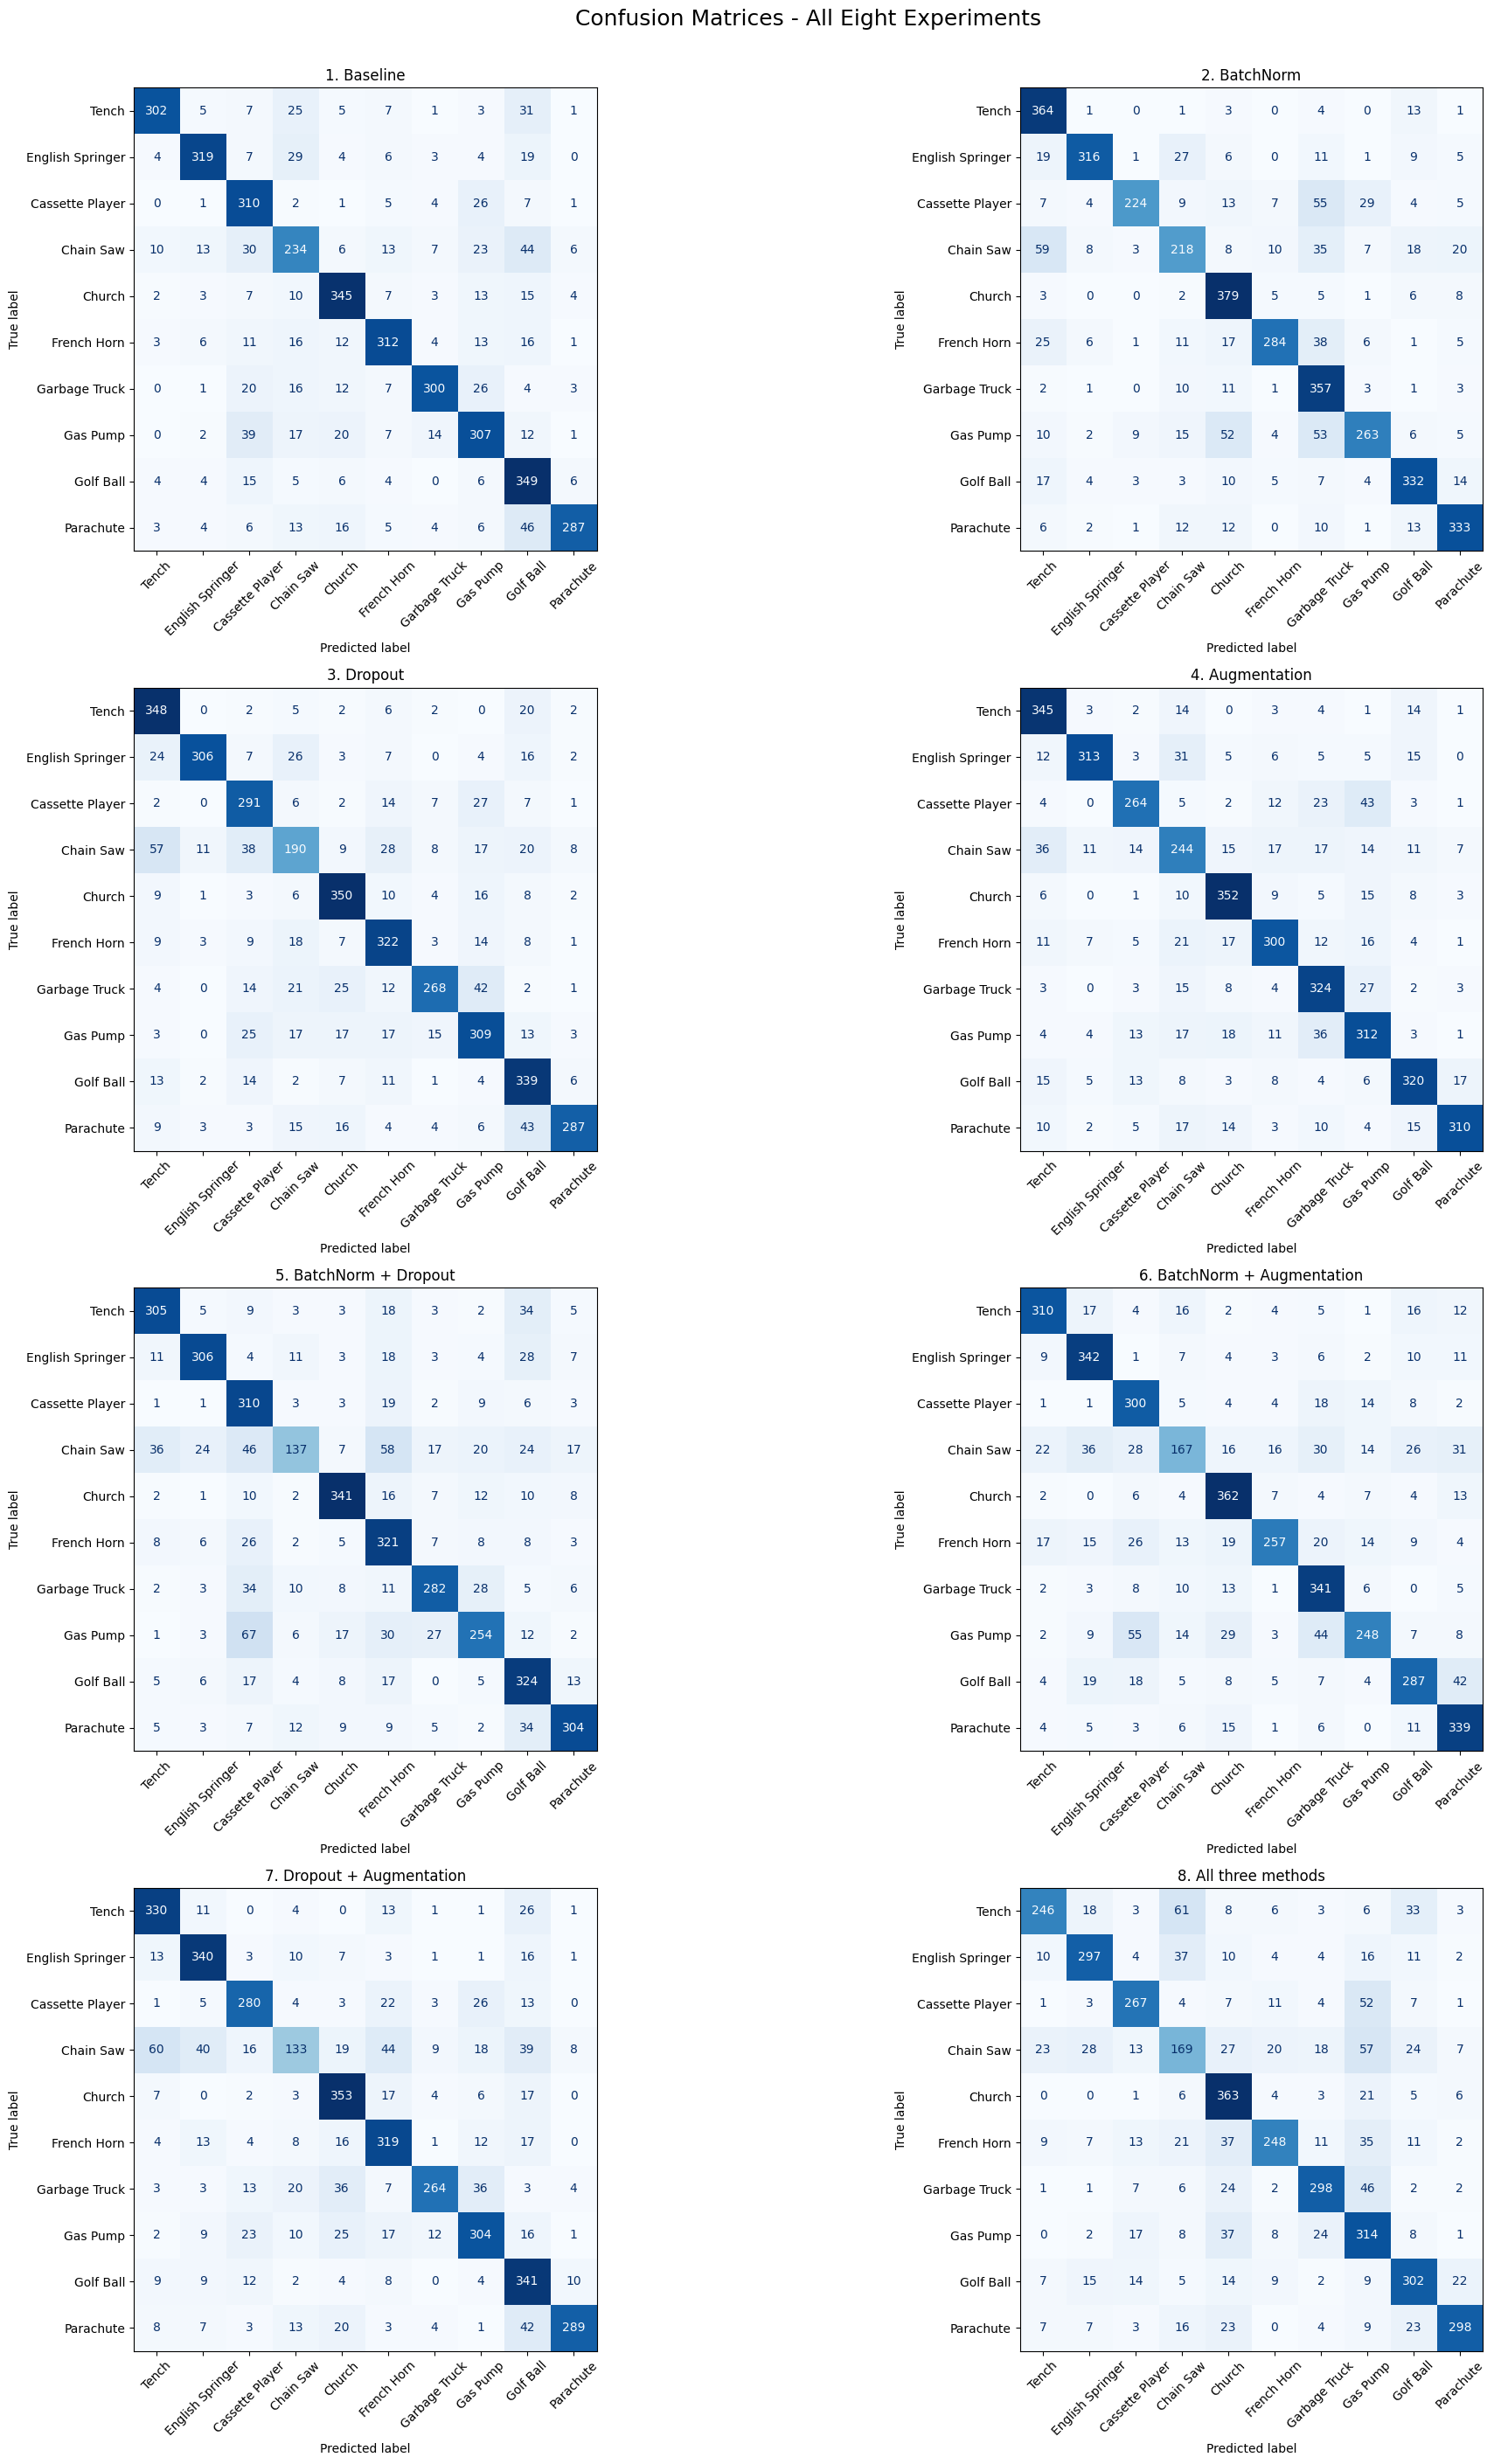

In [ ]:
# 10. Plot all eight confusion matrixes

class_name_map = {
    "n01440764": "Tench",
    "n02102040": "English Springer",
    "n02979186": "Cassette Player",
    "n03000684": "Chain Saw",
    "n03028079": "Church",
    "n03394916": "French Horn",
    "n03417042": "Garbage Truck",
    "n03425413": "Gas Pump",
    "n03445777": "Golf Ball",
    "n03888257": "Parachute"
}

plot_class_names = [
    class_name_map.get(class_id, class_id)
    for class_id in val_dataset.classes
]

fig, axes = plt.subplots(4, 2, figsize=(22, 28))

fig.suptitle(
    "Confusion Matrices - All Eight Experiments",
    fontsize=18,
    y=1.005
)

for ax, (name, result) in zip(axes.flat, final_results.items()):

    cm = confusion_matrix(
        result["labels"],
        result["predictions"],
        labels=range(num_classes)
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=plot_class_names
    ).plot(
        ax=ax,
        cmap="Blues",
        xticks_rotation=45,
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name, fontsize=12)

plt.tight_layout()
plt.savefig("task2_all8_confusion_matrixes.png", dpi=300, bbox_inches="tight")
plt.show()